# Expected goals (xG) model

A logistic regression that gives the probability that a shot is scored:

$$p(\text{goal}) = \sigma(\beta_0 + \beta_1 d + \beta_2 \theta)$$

where $d$ is the distance to goal and $\theta$ the shooting angle.

In [11]:
import pandas  as pd

from sklearn.linear_model import LogisticRegression

In [12]:
shots = pd.read_parquet("shots.parquet")
X, y = shots[["distance", "angle"]], shots["goal"]

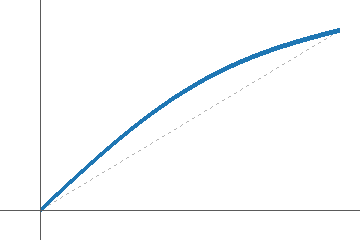

In [13]:
model = LogisticRegression(C=0.5)
model.fit(X, y)
plot_calibration(model, X, y)

In [14]:
shots.groupby("shot_type").agg(shots=("goal", "size"), goals=("goal", "sum"), mean_xG=("xG", "mean"))

,shot_type,shots,goals,mean_xG
0,foot,8412,903,0.108
1,header,1730,141,0.083
2,other,212,19,0.091


In [15]:
scores = cross_val_score(model, X, y, cv=5, scoring="neg_log_loss")
print(scores.mean())

-1.2871
